# ` Intelligent E-Commerce Customer Analytics Platform `

# Step 1: Import Required Libraries

In [41]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder


from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)
from sklearn.metrics import mean_absolute_percentage_error


In [20]:
# ------  Load Customer Features -------------
file_path = r"C:\Users\RAaM\OneDrive\Desktop\E-Commerce Customer Analytics\data\processed\customer_features.csv"

customer_features = pd.read_csv(file_path)
print("Dataset Shape:", customer_features.shape)
customer_features.head()

Dataset Shape: (96096, 12)


,customer_unique_id,Total_Orders,Total_Spending,Average_Order_Value,Average_Basket_Size,Recency,Frequency,Monetary,Customer_Tenure,Days_Since_Last_Purchase,Average_Review_Rating,Preferred_Payment_Method
0,861eff4711a542e4b93843c6dd7febb0,1,146.87,146.87,1.0,520,1,146.87,0,520,4.0,credit_card
1,290c77bc529b7ac935b93aa66c333dc3,1,335.48,335.48,1.0,278,1,335.48,0,278,5.0,credit_card
2,060e732b5b29e8181a18229c7b0b2b5e,1,157.73,157.73,1.0,152,1,157.73,0,152,5.0,credit_card
3,259dac757896d24d7702b9acbbff3f3c,1,173.30,173.30,1.0,219,1,173.30,0,219,5.0,credit_card
4,345ecd01c38d18a9036ed96c73b8d066,1,252.25,252.25,1.0,81,1,252.25,0,81,5.0,credit_card


In [21]:
# -------  Prepare Dataset for CLV Prediction ----------

# Target Variable
y = customer_features["Total_Spending"]

# Feature Matrix
X = customer_features.drop(
    columns=[
        "customer_unique_id",      # Identifier
        "Total_Spending",          # Target
        "Monetary",                # Target leakage
        "Average_Order_Value"      # Derived from target
    ]
)

print("Feature Shape :", X.shape)
print("Target Shape  :", y.shape)

print("\nFeatures Used:")
print(X.columns.tolist())

Feature Shape : (96096, 8)
Target Shape  : (96096,)

Features Used:
['Total_Orders', 'Average_Basket_Size', 'Recency', 'Frequency', 'Customer_Tenure', 'Days_Since_Last_Purchase', 'Average_Review_Rating', 'Preferred_Payment_Method']


In [22]:
# ----------- Test Train Split -----------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training Shape :", X_train.shape)
print("Testing Shape  :", X_test.shape)

# ----------- Preprocessing -----------
categorical_features = ["Preferred_Payment_Method"]
numeric_features = [
    col for col in X.columns
    if col not in categorical_features
]
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor_reg = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

Training Shape : (76876, 8)
Testing Shape  : (19220, 8)


#  Model 1: Logistic Regression 

In [23]:
# Building Pipeline 

lr_pipeline = Pipeline([
    ("preprocessor", preprocessor_reg),
    ("model", LinearRegression())
])
lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)

# Evaluation
mask = y_test != 0

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
mape_lr = np.mean(np.abs((y_test[mask] - y_pred_lr[mask]) / y_test[mask])) * 100
r2_lr = r2_score(y_test, y_pred_lr)

print(f"MAE  : {mae_lr:.2f}")
print(f"RMSE : {rmse_lr:.2f}")
print(f"MAPE : {mape_lr:.2f}%")
print(f"R²   : {r2_lr:.4f}")

# Save the Results

regression_results = []
regression_results.append({
    "Model": "Linear Regression",
    "RMSE": rmse_lr,
    "MAE": mae_lr,
    "MAPE": mape_lr,
    "R² Score": r2_lr
})

MAE  : 154.65
RMSE : 374.12
MAPE : 133.92%
R²   : 0.1857


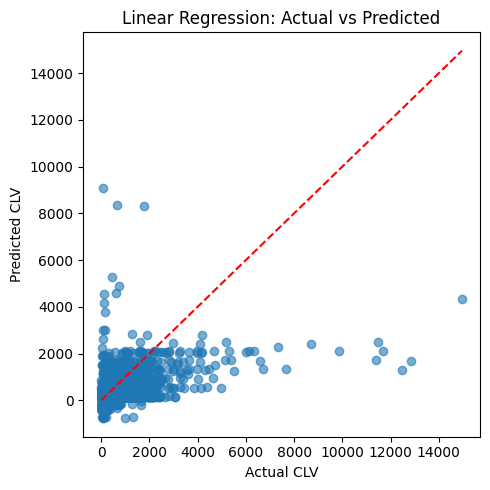

In [24]:
# Actual vs Predicted Plot

plt.figure(figsize=(5,5))
plt.scatter(y_test,y_pred_lr, alpha=0.6)
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual CLV")
plt.ylabel("Predicted CLV")
plt.title("Linear Regression: Actual vs Predicted")
plt.tight_layout()
plt.show()


# Interpretation
    # Points close to the red diagonal line indicate accurate predictions.
    # Large deviations indicate prediction errors.
    # The spread of the points provides a visual indication of model performance.

# Model 2 – Random Forest Regressor

In [25]:
# Building Pipeline
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor_reg),
    ("model", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])
rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)

# Evaluation
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mask = y_test > 0
mape_rf = np.mean(
    np.abs((y_test[mask] - y_pred_rf[mask]) / y_test[mask])
) * 100
r2_rf = r2_score(y_test, y_pred_rf)

print(f"MAE  : {mae_rf:.2f}")
print(f"RMSE : {rmse_rf:.2f}")
print(f"MAPE : {mape_rf:.2f}%")
print(f"R²   : {r2_rf:.4f}")

# Saving the Results
regression_results.append({
    "Model": "Random Forest",
    "RMSE": rmse_rf,
    "MAE": mae_rf,
    "MAPE": mape_rf,
    "R² Score": r2_rf
})

MAE  : 149.60
RMSE : 367.22
MAPE : 119.60%
R²   : 0.2154


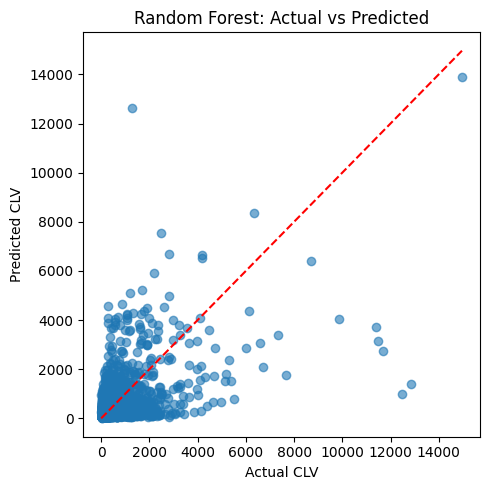

In [26]:
# Actual vs Predicted Results

plt.figure(figsize=(5,5))
plt.scatter(y_test,y_pred_rf,alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual CLV")
plt.ylabel("Predicted CLV")
plt.title("Random Forest: Actual vs Predicted")
plt.tight_layout()
plt.show()

# Model 3 – Gradient Boosting Regressor

In [28]:
# Build the Pipeline

gbr_pipeline = Pipeline([
    ("preprocessor", preprocessor_reg),
    ("model", GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        random_state=42
    ))
])
gbr_pipeline.fit(X_train, y_train)
y_pred_gbr = gbr_pipeline.predict(X_test)

# Evaluation
mask = y_test > 0
mae_gbr = mean_absolute_error(y_test, y_pred_gbr)
rmse_gbr = np.sqrt(mean_squared_error( y_test,y_pred_gbr))
mape_gbr = np.mean(np.abs((y_test[mask] - y_pred_gbr[mask]) / y_test[mask])) * 100
r2_gbr = r2_score(y_test, y_pred_gbr)

print(f"MAE  : {mae_gbr:.2f}")
print(f"RMSE : {rmse_gbr:.2f}")
print(f"MAPE : {mape_gbr:.2f}%")
print(f"R²   : {r2_gbr:.4f}")

# Save the results
regression_results.append({
    "Model": "Gradient Boosting",
    "RMSE": rmse_gbr,
    "MAE": mae_gbr,
    "MAPE": mape_gbr,
    "R² Score": r2_gbr
})

MAE  : 140.14
RMSE : 378.89
MAPE : 116.63%
R²   : 0.1648


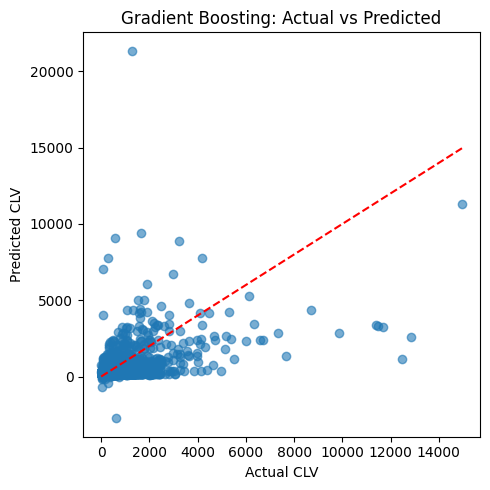

In [30]:
# Actual vs Predicted results

plt.figure(figsize=(5,5))
plt.scatter(y_test,y_pred_gbr, alpha=0.6)
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual CLV")
plt.ylabel("Predicted CLV")
plt.title("Gradient Boosting: Actual vs Predicted")
plt.tight_layout()
plt.show()

# Model 4 – XGBoost Regressor

In [32]:
# Building the pipeline

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor_reg),
    ("model", XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])
xgb_pipeline.fit(X_train, y_train)
y_pred_xgb = xgb_pipeline.predict(X_test)

# Evaluation
mask = y_test > 0
mae_xgb = mean_absolute_error(y_test,y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error( y_test,y_pred_xgb))
mape_xgb = np.mean(np.abs((y_test[mask] - y_pred_xgb[mask]) /y_test[mask])) * 100
r2_xgb = r2_score(y_test,y_pred_xgb)

print(f"MAE  : {mae_xgb:.2f}")
print(f"RMSE : {rmse_xgb:.2f}")
print(f"MAPE : {mape_xgb:.2f}%")
print(f"R²   : {r2_xgb:.4f}")

# Saving the Results
regression_results.append({
    "Model": "XGBoost",
    "RMSE": rmse_xgb,
    "MAE": mae_xgb,
    "MAPE": mape_xgb,
    "R² Score": r2_xgb
})

MAE  : 141.43
RMSE : 391.30
MAPE : 116.38%
R²   : 0.1092


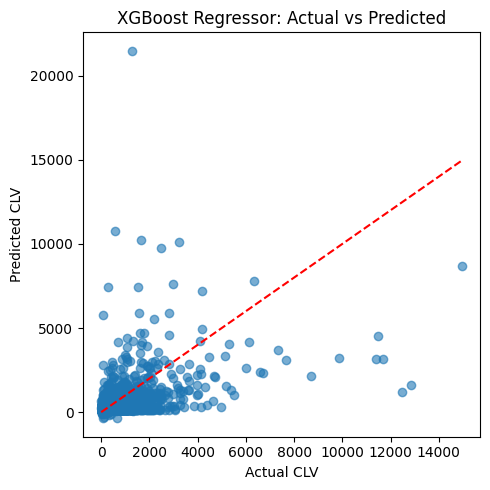

In [33]:
# Actual vs Predicted Results

plt.figure(figsize=(5,5))
plt.scatter(y_test,y_pred_xgb,alpha=0.6)
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual CLV")
plt.ylabel("Predicted CLV")
plt.title("XGBoost Regressor: Actual vs Predicted")
plt.tight_layout()
plt.show()

# Model 5: CatBoost Regressor

In [34]:
!pip3 install catboost

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   ---------------------------------------- 0.5/100.2 MB 2.4 MB/s eta 0:00:42
    --------------------------------------- 1.3/100.2 MB 2.8 MB/s eta 0:00:36
    --------------------------------------- 1.8/100.2 MB 2.9 MB/s eta 0:00:35
   - -------------------------------------- 2.6/100.2 MB 3.1 MB/s eta 0:00:32
   - -------------------------------------- 3.7/100.2 MB 3.4 MB/s eta 0:00:29
   - -------------------------------------- 4.2/100.2 MB 3.3 MB/s eta 0:00:30
   - -------------------------------------- 5.0/100.2 MB 3.3 MB/s eta 0:00:29
   -- ------------------------------------- 5.5/100.2 MB 3.2 MB/s eta 0:00:30
   -- ------------------------------------- 6.3/100.2 MB 3.2 MB/s eta 0:00:30
   -- ------------------------------------- 6.8/100.2 MB 3.2 MB/s eta 0:00:30



[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
# Building the pipeline

cat_pipeline = Pipeline([
    ("preprocessor", preprocessor_reg),
    ("model", CatBoostRegressor(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=0
    ))
])
cat_pipeline.fit(X_train, y_train)
y_pred_cat = cat_pipeline.predict(X_test)

# Evaluation
mask = y_test > 0
mae_cat = mean_absolute_error(y_test,y_pred_cat)
rmse_cat = np.sqrt(mean_squared_error(y_test,y_pred_cat))
mape_cat = np.mean(np.abs((y_test[mask] - y_pred_cat[mask])/ y_test[mask] )) * 100
r2_cat = r2_score(y_test,y_pred_cat)

print(f"MAE  : {mae_cat:.2f}")
print(f"RMSE : {rmse_cat:.2f}")
print(f"MAPE : {mape_cat:.2f}%")
print(f"R²   : {r2_cat:.4f}")

# Saving the Results

regression_results.append({
    "Model": "CatBoost",
    "RMSE": rmse_cat,
    "MAE": mae_cat,
    "MAPE": mape_cat,
    "R² Score": r2_cat
})

MAE  : 136.87
RMSE : 331.97
MAPE : 116.30%
R²   : 0.3588


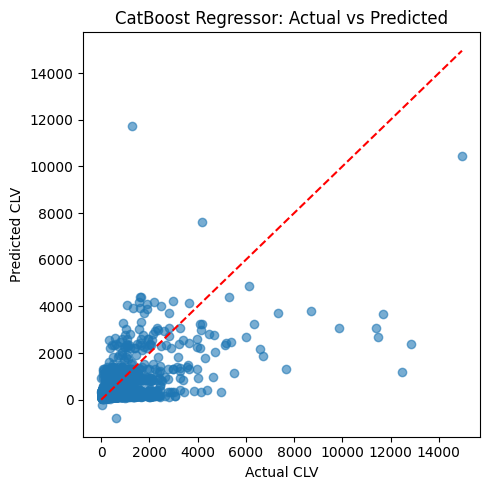

In [37]:
# Actual vs Predicted Results

plt.figure(figsize=(5,5))
plt.scatter(y_test,y_pred_cat,alpha=0.6)
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],"r--")
plt.xlabel("Actual CLV")
plt.ylabel("Predicted CLV")
plt.title("CatBoost Regressor: Actual vs Predicted")
plt.tight_layout()
plt.show()

# Saving the best model

In [40]:
regression_results_df = (
    pd.DataFrame(regression_results)
    .sort_values(by="R² Score", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

display(regression_results_df)

,Model,RMSE,MAE,MAPE,R² Score
0,CatBoost,331.9665,136.8661,116.3029,0.3588
1,Random Forest,367.2159,149.6022,119.5983,0.2154
2,Linear Regression,374.1172,154.6534,133.9202,0.1857
3,Gradient Boosting,378.8871,140.1361,116.6252,0.1648
4,XGBoost,391.2957,141.4320,116.3822,0.1092


# Interpretation
    - CatBoost provides the strongest overall performance for CLV prediction in your project.
# Key strengths include:
    - Lowest average prediction error (MAE)
    - Best handling of large errors (RMSE)
    - Highest explanatory power (R²)
    - Lowest percentage error (MAPE)
-This makes it the leading candidate for deployment.

In [42]:
joblib.dump( cat_pipeline,"../artifacts/catboost_clv_model.pkl")
print("CatBoost CLV model saved successfully.")

CatBoost CLV model saved successfully.
